# 04 · Detección de tuberculosis con características radiómicas

Entrenamiento y evaluación de los clasificadores de TB a partir de las características radiómicas extraídas dentro de cada segmentación pulmonar.

La pregunta sobre la que se basa el proyecto no es definir que clasificador es mejor, sino que su objetivo es determinar si **la técnica de segmentación cambia el desempeño en la detección de TB**. Por eso, cada clasificador es entrenado una vez por cada una de las técnicas de segmentación, utilizando las mismas características (misma partición, mismo protocolo, folds y busqueda de hiperparámetros). Entre pruebas, solamente cambia la técnica de segmentación de la que vienen las características.

| Sección | Contenido |
|---|---|
| 1 | Configuración del experimento |
| 2 | Entrada: características de `03_radiomica` |
| 3 | Partición y folds |
| 4 | Clasificadores |
| 5 | Protocolo |
| 6 | Desarrollo: validación cruzada interna |
| 7 | Evaluación en el conjunto de prueba |
| 8 | Comparación entre técnicas de segmentación |
| 9 | Importancia de características |
| 10 | Guardado |

## 1 · Configuración

Todo lo que cambia entre experimentos está en la celda siguiente:

- `DATASET`: dataset del que salen las características.
- `METHODS`: técnicas de segmentación a comparar.
- `FEATURE_CLASSES`: familias de pyradiomics que entran a los modelos. Para este experimento, unicamente se trabajara con las de primer orden (`firstorder`)
- `EXCLUDED_FEATURES`: características que no entran a los modelos.

In [1]:
import time
import warnings
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from tbseg.config import N_FOLDS, RESULTS_DIR, ROOT, SEED, SEGTRAIN_CSV

# ------------------------------------------------------------------ experimento
DATASET = "montgomery_shenzhen"
METHODS = ["unet", "attention_unet", "medsam", "deeplabv3plus"]     # técnicas de segmentación
FEATURE_CLASSES = ["firstorder"]
EXCLUDED_FEATURES = ["TotalEnergy"]

N_BOOTSTRAP = 5000

ID_COLS = ["image_id", "patient_id", "source", "tb", "split"]
RADIOMICS_DIR = RESULTS_DIR / "radiomics"
CLF_RESULTS_DIR = RESULTS_DIR / "classification" / DATASET / "+".join(FEATURE_CLASSES)

display(pd.Series({
    "Dataset": DATASET,
    "Técnicas de segmentación": ", ".join(METHODS),
    "Familias de características": ", ".join(FEATURE_CLASSES),
    "Características excluidas": ", ".join(EXCLUDED_FEATURES),
    "Folds internos": N_FOLDS,
    "Remuestreos bootstrap": N_BOOTSTRAP,
    "Semilla": SEED,
}).to_frame("valor").rename_axis("parámetro"))

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
METHOD_NAMES = {"unet": "U-Net", "attention_unet": "Attention U-Net", "medsam": "MedSAM", "deeplabv3plus": "DeepLabV3+"}
METHOD_COLORS = {"unet": "#2a78d6", "attention_unet": "#1baf7a", "medsam": "#eb6834", "deeplabv3plus": "#8a5cc2"}
MODEL_NAMES = {"svm": "SVM", "random_forest": "Random Forest", "mlp": "Red neuronal"}
NAMES = {**METHOD_NAMES, **MODEL_NAMES, "montgomery": "Montgomery", "shenzhen": "Shenzhen"}


def name(key):
    return NAMES.get(key, key)

,valor
parámetro,
Dataset,montgomery_shenzhen
Técnicas de segmentación,"unet, attention_unet, medsam, deeplabv3plus"
Familias de características,firstorder
Características excluidas,TotalEnergy
Folds internos,5
Remuestreos bootstrap,5000
Semilla,42


## 2 · Entrada: características de `03_radiomica`

`src/tbseg/radiomics/extract.py` escribe un CSV por técnica y familia, y `03_radiomica` los revisa:


| Columna | Contenido |
|---|---|
| `image_id` | Identificador de la imagen. Una fila por imagen. |
| `patient_id` | Paciente. Agrupa las radiografías de un mismo paciente. |
| `source` | Fuente: `montgomery` o `shenzhen`. |
| `tb` | Etiqueta: 1 = TB, 0 = normal. |
| `split` | Partición: `train`, `val` o `test`. |
| Resto | Características, con el nombre de pyradiomics sin prefijo (`Mean`, `Energy`, …). |

Con `firstorder` entran a los modelos **17 de las 18 características**: se excluye `TotalEnergy`, idéntica a `Energy`. Las demás correlacionadas se conservan.

La celda se detiene si falta un archivo o una columna de identificación, si hay un `image_id` repetido, si hay valores faltantes o infinitos, o si dos técnicas no tienen las mismas imágenes y características.

In [2]:
def load_table(method: str) -> pd.DataFrame:
    # Tabla de una técnica, ordenada por image_id: identificadores y características de cada familia
    tables = []
    for feature_class in FEATURE_CLASSES:
        path = RADIOMICS_DIR / f"{DATASET}_{feature_class}_{method}.csv"
        if not path.exists():
            raise FileNotFoundError(f"No existe {path}. Falta: python -m tbseg.radiomics.extract --method {method}")
        table = pd.read_csv(path)
        absent = [c for c in ID_COLS if c not in table.columns]
        if absent:
            raise ValueError(f"{path.name}: faltan las columnas {absent}")
        if table["image_id"].duplicated().any():
            raise ValueError(f"{path.name}: hay image_id repetidos")
        tables.append(table.sort_values("image_id", ignore_index=True).drop(columns=EXCLUDED_FEATURES, errors="ignore"))

    ids = tables[0][ID_COLS]
    if not all(table[ID_COLS].equals(ids) for table in tables):
        raise ValueError(f"{method}: las familias no tienen las mismas imágenes")
    merged = pd.concat([ids, *(table.drop(columns=ID_COLS) for table in tables)], axis=1)
    if merged.columns.duplicated().any():
        raise ValueError(f"{method}: hay características repetidas entre familias")
    return merged


tables = {method: load_table(method) for method in METHODS}
labels = tables[METHODS[0]][ID_COLS]
FEATURES = [c for c in tables[METHODS[0]].columns if c not in ID_COLS]

for method, table in tables.items():
    if not table[ID_COLS].equals(labels):
        raise ValueError(f"{method}: las imágenes no coinciden con las de {METHODS[0]}")
    if [c for c in table.columns if c not in ID_COLS] != FEATURES:
        raise ValueError(f"{method}: las características no coinciden con las de {METHODS[0]}")
    if not np.isfinite(table[FEATURES].to_numpy(dtype=float)).all():
        raise ValueError(f"{method}: hay valores faltantes o infinitos")

print(f"{len(labels)} imágenes de {labels['patient_id'].nunique()} pacientes | {len(FEATURES)} características:")
print(FEATURES)

704 imágenes de 701 pacientes | 17 características:
['10Percentile', '90Percentile', 'Energy', 'Entropy', 'InterquartileRange', 'Kurtosis', 'Maximum', 'MeanAbsoluteDeviation', 'Mean', 'Median', 'Minimum', 'Range', 'RobustMeanAbsoluteDeviation', 'RootMeanSquared', 'Skewness', 'Uniformity', 'Variance']


## 3 · Partición y folds

Se usa la misma partición de las redes de segmentación y de `03_radiomica`, por paciente y estratificada por fuente y diagnóstico:

| Conjunto | Particiones | Imágenes | Uso |
|---|---|---|---|
| Desarrollo | `train` + `val` | 563 | Elegir hiperparámetros y entrenar |
| Prueba | `test` | 141 | Evaluar una sola vez |

`val` solo servía para la detención temprana de las redes de segmentación. Los clasificadores no la necesitan, así que se une a `train`, igual que en `03_radiomica`.

Los hiperparámetros se eligen con **folds internos** dentro de desarrollo, calculados con `StratifiedGroupKFold`:
- **Agrupados por paciente**: las radiografías de un mismo paciente quedan en el mismo fold, para no validar con un paciente que el modelo ya vio.
- **Estratificados por fuente y diagnóstico a la vez**: cada fold conserva la proporción de Montgomery/Shenzhen y de TB/normal.
- **Los mismos para todas las técnicas y todos los clasificadores**, lo que permite comparar técnicas fold a fold (sección 6).

La celda se detiene si un paciente aparece en dos particiones o si la partición del CSV no coincide con `data/metadata/segtrain_split.csv`. En ese caso hay que repetir la extracción: el CSV vendría de una partición anterior.

In [3]:
if set(labels["split"]) != {"train", "val", "test"}:
    raise ValueError(f"Particiones inesperadas: {sorted(labels['split'].unique())}")
if (labels.groupby("patient_id")["split"].nunique() > 1).any():
    raise ValueError("Un paciente quedó en dos particiones")
if DATASET == "montgomery_shenzhen":
    reference = pd.read_csv(SEGTRAIN_CSV).sort_values("image_id", ignore_index=True)[ID_COLS]
    if not labels.equals(reference):
        raise ValueError(f"Los CSV no coinciden con {SEGTRAIN_CSV.name}: hay que repetir la extracción")

is_test = labels["split"].eq("test").to_numpy()
dev, test = labels[~is_test].reset_index(drop=True), labels[is_test].reset_index(drop=True)
X_dev = {method: table.loc[~is_test, FEATURES] for method, table in tables.items()}
X_test = {method: table.loc[is_test, FEATURES] for method, table in tables.items()}

strata = dev["source"] + "_" + dev["tb"].astype(str)
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
INNER_SPLITS = list(cv.split(dev, strata, groups=dev["patient_id"]))
fold = np.empty(len(dev), dtype=int)
for k, (_, validation) in enumerate(INNER_SPLITS):
    fold[validation] = k
assert (dev.assign(fold=fold).groupby("patient_id")["fold"].nunique() == 1).all(), "un paciente quedó en dos folds"

TB_NAMES = {0: "no TB", 1: "TB"}
display(pd.crosstab([labels["source"], labels["tb"].map(TB_NAMES)], np.where(is_test, "prueba", "desarrollo"),
                    colnames=["conjunto"], margins=True, margins_name="total"))
display(pd.crosstab([dev["source"], dev["tb"].map(TB_NAMES)], fold,
                    colnames=["fold interno"], margins=True, margins_name="total"))

conjunto          desarrollo  prueba  total
source     tb                              
montgomery TB             47      11     58
           no TB          64      16     80
shenzhen   TB            229      58    287
           no TB         223      56    279
total                    563     141    704

fold interno        0    1    2    3    4  total
source     tb                                   
montgomery TB      10   11    9    8    9     47
           no TB   12   13   13   13   13     64
shenzhen   TB      46   46   46   46   45    229
           no TB   44   44   45   45   45    223
total             112  114  113  112  112    563

## 4 · Clasificadores

Cada clasificador es un `Pipeline` de scikit-learn. La estandarización va dentro del pipeline, así que se ajusta **solo con las imágenes de entrenamiento de cada fold**.

| Paso | SVM | Random Forest | Red neuronal | Para qué |
|---|---|---|---|---|
| `StandardScaler()` | ✓ | | ✓ | El kernel RBF usa distancias y la red ajusta sus pesos por gradiente: sin escalar, la característica de mayor rango domina (`Energy` es del orden de 10⁹ a 10¹⁰). Los árboles no dependen de la escala. |
| Clasificador | `SVC(kernel="rbf")` | `RandomForestClassifier(300 árboles)` | 5 × `MLPClassifier` | |

`class_weight="balanced"` pondera las clases según su frecuencia en el entrenamiento. En desarrollo cambia poco (276 TB y 287 normales), pero evita que un desbalance futuro sesgue el modelo hacia la clase mayoritaria.

### 4.1 Red neuronal: qué tipo y por qué

**Se usa un perceptrón multicapa (MLP).** La propuesta pide entrenar redes neuronales con las características extraídas de cada segmentación (metodología, fase 3). Cada radiografía llega a esta etapa como un vector de 17 números. El MLP recibe un vector de longitud fija, combina todas las características en cada capa y no supone ningún orden entre ellas.

| Tipo de red | Qué recibe | Decisión |
|---|---|---|
| **MLP** | Vector de características | **Se usa.** Entra en el mismo `Pipeline`, `GridSearchCV` y folds internos de SVM y Random Forest. |
| CNN sobre la radiografía (ResNet, DenseNet, …) | Imagen | Se descarta. Aprendería de los píxeles, así que no mediría la capacidad discriminativa de las características radiómicas (objetivo específico 3). |
| CNN 1D o red recurrente | Secuencia | Se descarta. Suponen que la posición importa, y el orden de las columnas es arbitrario. |
| Transformer tabular (FT-Transformer) | Vector | Se descarta. Sus mejores resultados en Gorishniy et al. (2021) vienen de datasets con 20 640 muestras o más; aquí hay 563 imágenes. |

**Qué esperar.** Kadra et al. (2021) encuentran que un MLP bien regularizado supera a arquitecturas especializadas en datos tabulares. Grinsztajn et al. (2022) encuentran que, con unas 10 000 muestras, los modelos de árboles siguen por encima de las redes. Ninguno usa radiómica ni un tamaño de muestra como este: orientan el diseño, pero no predicen el resultado. La red no tiene por qué superar a Random Forest. Aquí permite comprobar si el efecto de la segmentación se repite con un clasificador de otra familia.

**Antecedentes.** Vajda et al. (2018) usan una red neuronal con características manuales en Montgomery y Shenzhen. Santosh y Antani (2018) combinan por voto un MLP, una red bayesiana y un Random Forest. Usan otras características, así que sus valores no se comparan con los de este notebook.

**Configuración**

| Elemento | Valor | Motivo |
|---|---|---|
| Implementación | `MLPClassifier` de scikit-learn | Con 17 características cada red entrena en segundos, en CPU y sin bucle de entrenamiento propio. |
| Capas ocultas | `(8,)`, `(16, 8)`, `(32, 16)` o `(64, 32)` | Se eligen en la rejilla, por técnica, como los hiperparámetros de SVM y Random Forest. |
| `alpha` (regularización L2) | 0,1, 1 o 10 | Igual. |
| Optimizador, activación | Adam, ReLU | Sección 6.4. |
| Detención temprana | No | Sección 6.4. |
| Épocas | Hasta 3000 | Sección 6.3. |
| Redes por clasificador | 5, promediadas | Ver abajo y sección 6.4. |

**Promedio de 5 redes.** Una red depende de sus pesos iniciales aleatorios. Para reducir ese azar, que se mezclaría con el efecto de la segmentación, el clasificador promedia la probabilidad de 5 redes que entrenan con las mismas imágenes y solo difieren en sus pesos iniciales (`BaggingClassifier` con `bootstrap=False`; Lakshminarayanan et al., 2017).

**Pesos de clase.** `MLPClassifier` no tiene `class_weight`. En desarrollo esos pesos serían 1,02 (TB) y 0,98 (normal), así que no se agregan.

**Referencias**

- Gorishniy, Y., Rubachev, I., Khrulkov, V., & Babenko, A. (2021). Revisiting deep learning models for tabular data. *NeurIPS 2021*. https://arxiv.org/abs/2106.11959
- Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS 2022*. https://arxiv.org/abs/2207.08815
- Kadra, A., Lindauer, M., Hutter, F., & Grabocka, J. (2021). Well-tuned simple nets excel on tabular datasets. *NeurIPS 2021*. https://arxiv.org/abs/2106.11189
- Lakshminarayanan, B., Pritzel, A., & Blundell, C. (2017). Simple and scalable predictive uncertainty estimation using deep ensembles. *NIPS 2017*. https://arxiv.org/abs/1612.01474
- Santosh, K. C., & Antani, S. (2018). Automated chest X-ray screening: Can lung region symmetry help detect pulmonary abnormalities? *IEEE Transactions on Medical Imaging*, 37(5), 1168–1177. https://doi.org/10.1109/TMI.2017.2775636
- Vajda, S., et al. (2018). Feature selection for automatic tuberculosis screening in frontal chest radiographs. *Journal of Medical Systems*, 42(8), 146. https://doi.org/10.1007/s10916-018-0991-9

In [4]:
MODELS = {
    "svm": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", class_weight="balanced")),
        ]),
        {"clf__C": [0.1, 1, 10, 100, 1000], "clf__gamma": ["scale", 0.001, 0.01, 0.1]},
    ),
    "random_forest": (
        Pipeline([
            ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED)),
        ]),
        {"clf__max_depth": [None, 10], "clf__min_samples_leaf": [1, 5], "clf__max_features": ["sqrt", 0.5]},
    ),
    "mlp": (
        Pipeline([
            ("scaler", StandardScaler()),
            # bootstrap=False: las 5 redes entrenan con las mismas imágenes y solo cambian sus pesos iniciales
            ("clf", BaggingClassifier(MLPClassifier(solver="adam", activation="relu", max_iter=3000),
                                      n_estimators=5, bootstrap=False, random_state=SEED)),
        ]),
        {"clf__estimator__hidden_layer_sizes": [(8,), (16, 8), (32, 16), (64, 32)], "clf__estimator__alpha": [0.1, 1, 10]},
    ),
}

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame([
        {"modelo": name(m), "rejilla": "; ".join(f"{k.split('__')[-1]}: {v}" for k, v in grid.items()),
         "combinaciones": int(np.prod([len(v) for v in grid.values()]))}
        for m, (_, grid) in MODELS.items()
    ]).set_index("modelo"))

,rejilla,combinaciones
modelo,,
SVM,"C: [0.1, 1, 10, 100, 1000]; gamma: ['scale', 0.001, 0.01, 0.1]",20
Random Forest,"max_depth: [None, 10]; min_samples_leaf: [1, 5]; max_features: ['sqrt', 0.5]",8
Red neuronal,"hidden_layer_sizes: [(8,), (16, 8), (32, 16), (64, 32)]; alpha: [0.1, 1, 10]",12


## 5 · Protocolo

Dos etapas, para que el conjunto de prueba no influya en ninguna decisión:

```
Desarrollo (train + val)
    └─ GridSearchCV con 5 folds internos elige los hiperparámetros por AUC
    └─ reentrena con todo el desarrollo
Prueba (test)
    └─ el modelo ya fijo predice cada imagen una sola vez
```

**Métricas:**
- **AUC** (métrica principal): probabilidad de que una radiografía TB reciba un puntaje mayor que una no-TB. No depende del umbral.
- **Sensibilidad**: fracción de casos TB detectados.
- **Especificidad**: fracción de casos no-TB descartados correctamente.
- **Exactitud balanceada**: media de sensibilidad y especificidad.
- **F1**: media armónica de precisión y sensibilidad.

Sensibilidad, especificidad, exactitud balanceada y F1 usan el umbral por defecto de cada modelo (SVM: distancia 0 al hiperplano; Random Forest y red neuronal: probabilidad 0,5).

In [5]:
METRICS = ["auc", "sensibilidad", "especificidad", "exactitud_balanceada", "f1"]


def positive_score(model, X):
    # Puntaje de la clase TB: probabilidad (Random Forest, red neuronal) o distancia al hiperplano (SVM)
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def compute_metrics(y, pred, score) -> dict:
    tp, fn = np.sum((pred == 1) & (y == 1)), np.sum((pred == 0) & (y == 1))
    tn, fp = np.sum((pred == 0) & (y == 0)), np.sum((pred == 1) & (y == 0))
    sensitivity, specificity = tp / (tp + fn), tn / (tn + fp)
    return {
        "auc": roc_auc_score(y, score),
        "sensibilidad": sensitivity,
        "especificidad": specificity,
        "exactitud_balanceada": (sensitivity + specificity) / 2,
        "f1": 2 * tp / (2 * tp + fp + fn),
    }


searches = {}
start = time.time()
for model_name, (pipeline, grid) in MODELS.items():
    for method in METHODS:
        t0 = time.time()
        search = GridSearchCV(clone(pipeline), grid, scoring="roc_auc", cv=INNER_SPLITS, n_jobs=-1)
        searches[model_name, method] = search.fit(X_dev[method], dev["tb"])
        print(f"{name(model_name):<13} | {name(method):>16} | {time.time() - t0:.0f} s")
print(f"Total: {(time.time() - start) / 60:.1f} min")

SVM           |            U-Net | 2 s


SVM           |  Attention U-Net | 0 s


SVM           |           MedSAM | 0 s


SVM           |       DeepLabV3+ | 0 s


Random Forest |            U-Net | 3 s


Random Forest |  Attention U-Net | 3 s


... (2 outputs left out)

Red neuronal  |            U-Net | 24 s


Red neuronal  |  Attention U-Net | 25 s


Red neuronal  |           MedSAM | 30 s


Red neuronal  |       DeepLabV3+ | 31 s
Total: 2.1 min


## 6 · Desarrollo: validación cruzada interna

Esta sección solo usa el conjunto de desarrollo.

### 6.1 Hiperparámetros elegidos

Media ± desviación de la AUC entre los folds internos, con la combinación elegida. Es ligeramente optimista porque es la mejor de la rejilla: sirve para revisar el entrenamiento, no como resultado final.

In [6]:
cv_metrics = pd.DataFrame([
    {"model": model_name, "method": method, "fold": k, "auc": search.cv_results_[f"split{k}_test_score"][search.best_index_]}
    for (model_name, method), search in searches.items() for k in range(N_FOLDS)
])
best_params = pd.DataFrame([
    {"model": model_name, "method": method, "auc_interna": search.best_score_,
     "params": str({k.split("__")[-1]: v for k, v in search.best_params_.items()})}
    for (model_name, method), search in searches.items()
])

deviation = cv_metrics.groupby(["model", "method"], sort=False)["auc"].std()
summary = best_params.set_index(["model", "method"])
summary.insert(0, "auc", summary["auc_interna"].map("{:.3f}".format) + " ± " + deviation.map("{:.3f}".format))
with pd.option_context("display.max_colwidth", None):
    display(summary.drop(columns="auc_interna").rename(index=name))

auc  \
model         method                           
SVM           U-Net            0.815 ± 0.050   
              Attention U-Net  0.825 ± 0.050   
              MedSAM           0.780 ± 0.035   
              DeepLabV3+       0.833 ± 0.057   
Random Forest U-Net            0.809 ± 0.049   
              Attention U-Net  0.831 ± 0.045   
              MedSAM           0.783 ± 0.033   
              DeepLabV3+       0.830 ± 0.061   
Red neuronal  U-Net            0.825 ± 0.048   
              Attention U-Net  0.847 ± 0.045   
              MedSAM           0.790 ± 0.013   
              DeepLabV3+       0.837 ± 0.055   

                                                                                         params  
model         method                                                                             
SVM           U-Net                                                   {'C': 100, 'gamma': 0.01}  
              Attention U-Net                                         {'C': 100, 'gamma': 0.01}  
              MedSAM                                                 {'C': 1, 'gamma': 'scale'}  
              DeepLabV3+                                              {'C': 100, 'gamma': 0.01}  
Random Forest U-Net               {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 1}  
              Attention U-Net   {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1}  
              MedSAM           {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 5}  
              DeepLabV3+          {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 1}  
Red neuronal  U-Net                                 {'alpha': 1, 'hidden_layer_sizes': (16, 8)}  
              Attention U-Net                      {'alpha': 1, 'hidden_layer_sizes': (64, 32)}  
              MedSAM                               {'alpha': 1, 'hidden_layer_sizes': (64, 32)}  
              DeepLabV3+                           {'alpha': 1, 'hidden_layer_sizes': (64, 32)}

### 6.2 AUC por fold interno

Cada línea gris une el mismo fold a través de las técnicas: las imágenes de validación son idénticas, así que la pendiente de la línea es el efecto de la técnica de segmentación en ese fold.

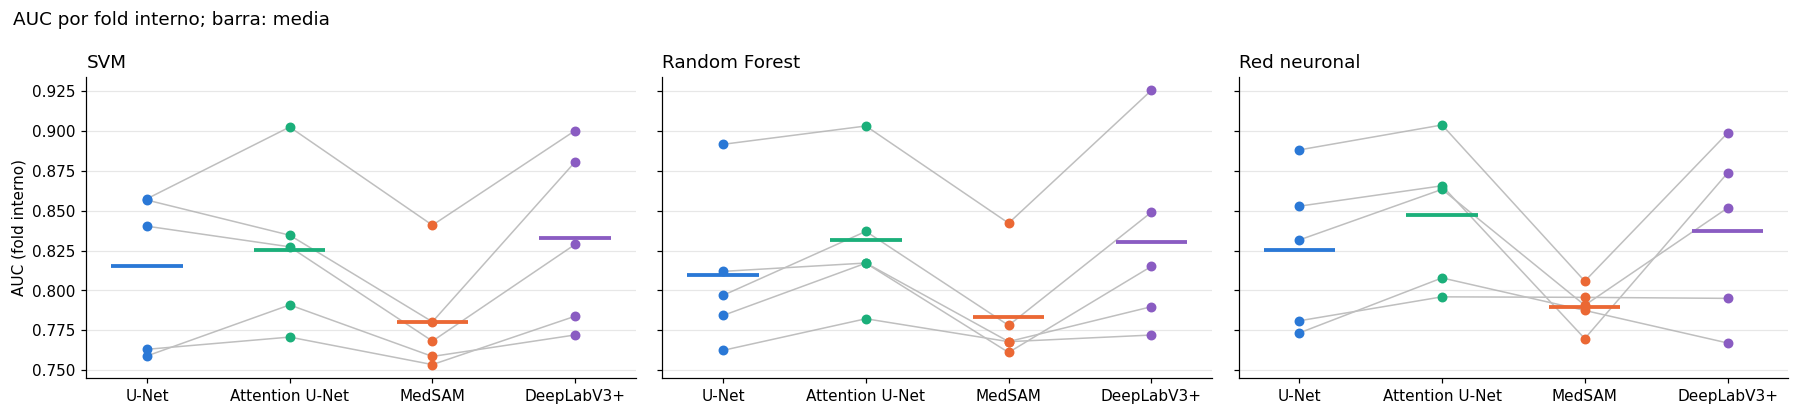

In [7]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(5.5 * len(MODELS), 3.8), sharey=True, squeeze=False)
for ax, model_name in zip(axes[0], MODELS):
    auc = cv_metrics[cv_metrics["model"] == model_name].pivot(index="fold", columns="method", values="auc")[METHODS]
    x = np.arange(len(METHODS))
    for _, row in auc.iterrows():
        ax.plot(x, row.to_numpy(), color="0.75", lw=1, zorder=1)
    for i, method in enumerate(METHODS):
        ax.scatter(np.full(len(auc), i), auc[method], color=METHOD_COLORS.get(method), s=30, zorder=2)
        ax.hlines(auc[method].mean(), i - 0.25, i + 0.25, color=METHOD_COLORS.get(method), lw=2.5, zorder=3)
    ax.set_xticks(x, [name(m) for m in METHODS])
    ax.set_title(name(model_name), loc="left"); ax.grid(axis="y", alpha=0.3)
axes[0, 0].set_ylabel("AUC (fold interno)")
fig.suptitle("AUC por fold interno; barra: media", x=0.01, ha="left")
fig.tight_layout()
plt.show()

### 6.3 Red neuronal: rejilla, sobreajuste y convergencia

La primera tabla muestra la AUC interna de cada combinación de la rejilla. La segunda compara la AUC en entrenamiento con la AUC interna, lo que indica el sobreajuste, y muestra las épocas de la red que más tardó: si llega a 3000, no convergió.

In [8]:
rows = []
for method in METHODS:
    results = searches["mlp", method].cv_results_
    for params, auc in zip(results["params"], results["mean_test_score"]):
        hidden = params["clf__estimator__hidden_layer_sizes"]
        rows.append({"hidden_layers": str(hidden), "parameters": sum((a + 1) * b for a, b in zip([len(FEATURES), *hidden], [*hidden, 1])),
                     "alpha": params["clf__estimator__alpha"], "method": method, "auc": auc})
mlp_selection = pd.DataFrame(rows)
display(mlp_selection.pivot_table(index=["hidden_layers", "parameters", "alpha"], columns="method", values="auc", sort=False)[METHODS]
        .rename_axis(index=["capas ocultas", "parámetros por red", "alpha"]).round(3).rename(columns=name))

display(pd.DataFrame([
    {"técnica": name(method),
     "AUC en entrenamiento": roc_auc_score(dev["tb"], positive_score(searches["mlp", method], X_dev[method])),
     "AUC interna": searches["mlp", method].best_score_,
     "épocas de la red más lenta": max(net.n_iter_ for net in searches["mlp", method].best_estimator_[-1].estimators_)}
    for method in METHODS
]).set_index("técnica").round(3))

method                                  U-Net  Attention U-Net  MedSAM  \
capas ocultas parámetros por red alpha                                   
(8,)          153                0.1    0.813            0.837   0.775   
                                 1.0    0.809            0.824   0.774   
                                 10.0   0.782            0.790   0.717   
(16, 8)       433                0.1    0.823            0.836   0.781   
                                 1.0    0.825            0.842   0.783   
                                 10.0   0.779            0.788   0.702   
(32, 16)      1121               0.1    0.808            0.825   0.770   
                                 1.0    0.822            0.846   0.789   
                                 10.0   0.780            0.788   0.697   
(64, 32)      3265               0.1    0.798            0.816   0.761   
                                 1.0    0.824            0.847   0.790   
                                 10.0   0.780            0.788   0.698   

method                                  DeepLabV3+  
capas ocultas parámetros por red alpha              
(8,)          153                0.1         0.827  
                                 1.0         0.825  
                                 10.0        0.792  
(16, 8)       433                0.1         0.833  
                                 1.0         0.832  
                                 10.0        0.788  
(32, 16)      1121               0.1         0.835  
                                 1.0         0.836  
                                 10.0        0.789  
(64, 32)      3265               0.1         0.832  
                                 1.0         0.837  
                                 10.0        0.789

,AUC en entrenamiento,AUC interna,épocas de la red más lenta
técnica,,,
U-Net,0.909,0.825,824
Attention U-Net,0.957,0.847,585
MedSAM,0.942,0.790,568
DeepLabV3+,0.961,0.837,608


**Lectura.**

*Hechos*

- **Regularización.** `alpha = 1` se elige en las cuatro técnicas. `alpha = 10` baja la AUC a 0,78–0,79 con las redes de segmentación y a 0,70–0,72 con MedSAM.
- **Arquitectura.** Con `alpha = 1`, las tres arquitecturas de dos capas difieren en 0,003 (U-Net), 0,005 (Attention U-Net), 0,007 (MedSAM) y 0,005 (DeepLabV3+). Se eligen `(16, 8)` en U-Net y `(64, 32)` en las otras tres.
- **Sobreajuste.** La AUC en entrenamiento supera a la interna en 0,084 (U-Net), 0,110 (Attention U-Net), 0,152 (MedSAM) y 0,124 (DeepLabV3+).
- **Convergencia.** La red más lenta usa 824 de las 3000 épocas.

*Interpretación*

- Con `alpha = 1`, el tamaño de la red importa poco: las diferencias son mucho menores que la desviación entre folds de la sección 6.1 en las redes de segmentación. `(64, 32)` queda en el borde superior de la rejilla, y la sección 6.4 comprueba que `(128, 64)` no mejora.
- Las técnicas no reciben la misma arquitectura, igual que SVM y Random Forest no reciben los mismos hiperparámetros: lo común es la búsqueda.

### 6.4 Red neuronal: semilla y opciones descartadas

La red depende de sus pesos iniciales aleatorios. Se repite la validación interna con 5 semillas, con la configuración elegida para cada técnica, usando 1 red y el promedio de 5 redes.

- **Primera tabla.** Media de AUC y F1, y cuánto cambian entre semillas dentro de un fold. Un fold tiene unas 112 imágenes, un tamaño parecido al del conjunto de prueba, que se evalúa una sola vez.
- **Segunda tabla.** Diferencia entre técnicas: `media`, `mínimo` y `máximo` entre semillas de la diferencia promediada entre folds, si conserva el signo en todas las semillas, y cuánto cambia entre semillas dentro de un fold. Una diferencia que cambia de signo con la semilla no se puede atribuir a la segmentación.
- **Tercera tabla.** AUC interna al cambiar una opción de la configuración elegida, con la semilla del proyecto. `capas (128, 64)` comprueba el borde superior de la rejilla.

In [9]:
N_SEEDS = 5


def internal_scores(method, **settings):
    # AUC y F1 por fold interno de la red elegida para una técnica, cambiando parte de su configuración
    model = clone(searches["mlp", method].best_estimator_).set_params(**settings)
    scores = cross_validate(model, X_dev[method], dev["tb"], scoring={"auc": "roc_auc", "f1": "f1"}, cv=INNER_SPLITS, n_jobs=-1)
    return pd.DataFrame({"fold": range(N_FOLDS), "auc": scores["test_auc"], "f1": scores["test_f1"]})


mlp_seeds = pd.concat([
    internal_scores(method, clf__n_estimators=nets, clf__random_state=seed).assign(method=method, nets=nets, seed=seed)
    for nets in (1, 5) for method in METHODS for seed in range(N_SEEDS)
], ignore_index=True)

SCORES = ["auc", "f1"]
by_seed = mlp_seeds.groupby(["nets", "method", "seed"], sort=False)[SCORES].mean()
within_fold = mlp_seeds.groupby(["nets", "method", "fold"], sort=False)[SCORES].std().groupby(["nets", "method"], sort=False).mean()
display(by_seed.groupby(["nets", "method"], sort=False).mean().add_prefix("media_").join(within_fold.add_prefix("desv_en_un_fold_"))
        .rename_axis(index=["redes", "técnica"]).round(4).rename(index=name))

rows = []
for nets in (1, 5):
    for score in SCORES:
        selected = mlp_seeds[mlp_seeds["nets"] == nets].pivot(index=["seed", "fold"], columns="method", values=score)
        for reference, method in combinations(METHODS, 2):
            difference = selected[method] - selected[reference]
            mean_by_seed = difference.groupby("seed").mean()
            rows.append({"redes": nets, "métrica": score, "referencia": name(reference), "técnica": name(method),
                         "media": mean_by_seed.mean(), "mínimo": mean_by_seed.min(), "máximo": mean_by_seed.max(),
                         "mismo signo": bool((mean_by_seed > 0).all() or (mean_by_seed < 0).all()),
                         "desv_en_un_fold": difference.groupby("fold").std().mean()})
if rows:
    display(pd.DataFrame(rows).set_index(["redes", "métrica", "referencia", "técnica"]).round(4))

VARIANTS = {
    "elegida": {},
    "capas (128, 64)": {"clf__estimator__hidden_layer_sizes": (128, 64)},
    "optimizador lbfgs": {"clf__estimator__solver": "lbfgs"},
    "activación tanh": {"clf__estimator__activation": "tanh"},
    "detención temprana": {"clf__estimator__early_stopping": True},
}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)  # lbfgs no siempre converge en 3000 iteraciones
    mlp_variants = pd.DataFrame([
        {"variant": variant, "method": method, "auc": internal_scores(method, **settings)["auc"].mean()}
        for variant, settings in VARIANTS.items() for method in METHODS
    ])
display(mlp_variants.pivot(index="variant", columns="method", values="auc").loc[list(VARIANTS), METHODS].round(4).rename(columns=name))

media_auc  media_f1  desv_en_un_fold_auc  \
redes técnica                                                     
1     U-Net               0.8216    0.7249               0.0100   
      Attention U-Net     0.8450    0.7370               0.0051   
      MedSAM              0.7877    0.7073               0.0075   
      DeepLabV3+          0.8364    0.7386               0.0058   
5     U-Net               0.8214    0.7299               0.0039   
      Attention U-Net     0.8461    0.7370               0.0028   
      MedSAM              0.7899    0.7071               0.0037   
      DeepLabV3+          0.8358    0.7403               0.0040   

                       desv_en_un_fold_f1  
redes técnica                              
1     U-Net                        0.0122  
      Attention U-Net              0.0167  
      MedSAM                       0.0203  
      DeepLabV3+                   0.0124  
5     U-Net                        0.0114  
      Attention U-Net              0.0110  
      MedSAM                       0.0151  
      DeepLabV3+                   0.0076

media  mínimo  máximo  \
redes métrica referencia      técnica                                   
1     auc     U-Net           Attention U-Net  0.0234  0.0192  0.0303   
                              MedSAM          -0.0340 -0.0389 -0.0303   
                              DeepLabV3+       0.0147  0.0117  0.0219   
              Attention U-Net MedSAM          -0.0573 -0.0606 -0.0537   
                              DeepLabV3+      -0.0086 -0.0108 -0.0068   
              MedSAM          DeepLabV3+       0.0487  0.0451  0.0522   
      f1      U-Net           Attention U-Net  0.0121  0.0009  0.0359   
                              MedSAM          -0.0177 -0.0393 -0.0102   
                              DeepLabV3+       0.0137  0.0011  0.0301   
              Attention U-Net MedSAM          -0.0298 -0.0463 -0.0136   
                              DeepLabV3+       0.0016 -0.0057  0.0119   
              MedSAM          DeepLabV3+       0.0314  0.0144  0.0467   
5     auc     U-Net           Attention U-Net  0.0246  0.0222  0.0268   
                              MedSAM          -0.0316 -0.0342 -0.0275   
                              DeepLabV3+       0.0144  0.0128  0.0160   
              Attention U-Net MedSAM          -0.0562 -0.0591 -0.0526   
                              DeepLabV3+      -0.0103 -0.0117 -0.0090   
              MedSAM          DeepLabV3+       0.0460  0.0414  0.0480   
      f1      U-Net           Attention U-Net  0.0071  0.0004  0.0135   
                              MedSAM          -0.0227 -0.0356 -0.0082   
                              DeepLabV3+       0.0104  0.0024  0.0153   
              Attention U-Net MedSAM          -0.0299 -0.0435 -0.0175   
                              DeepLabV3+       0.0033 -0.0024  0.0092   
              MedSAM          DeepLabV3+       0.0331  0.0235  0.0411   

                                               mismo signo  desv_en_un_fold  
redes métrica referencia      técnica                                        
1     auc     U-Net           Attention U-Net         True           0.0124  
                              MedSAM                  True           0.0111  
                              DeepLabV3+              True           0.0113  
              Attention U-Net MedSAM                  True           0.0088  
                              DeepLabV3+              True           0.0058  
              MedSAM          DeepLabV3+              True           0.0099  
      f1      U-Net           Attention U-Net         True           0.0204  
                              MedSAM                  True           0.0216  
                              DeepLabV3+              True           0.0155  
              Attention U-Net MedSAM                  True           0.0315  
                              DeepLabV3+             False           0.0207  
              MedSAM          DeepLabV3+              True           0.0237  
5     auc     U-Net           Attention U-Net         True           0.0052  
                              MedSAM                  True           0.0056  
                              DeepLabV3+              True           0.0053  
              Attention U-Net MedSAM                  True           0.0048  
                              DeepLabV3+              True           0.0037  
              MedSAM          DeepLabV3+              True           0.0055  
      f1      U-Net           Attention U-Net         True           0.0188  
                              MedSAM                  True           0.0178  
                              DeepLabV3+              True           0.0151  
              Attention U-Net MedSAM                  True           0.0203  
                              DeepLabV3+             False           0.0131  
              MedSAM          DeepLabV3+              True           0.0148

method,U-Net,Attention U-Net,MedSAM,DeepLabV3+
variant,,,,
elegida,0.8254,0.8473,0.7899,0.8372
"capas (128, 64)",0.8232,0.8472,0.7904,0.8383
optimizador lbfgs,0.7883,0.8042,0.7502,0.8292
activación tanh,0.8196,0.8463,0.7900,0.8384
detención temprana,0.7464,0.7834,0.7073,0.7870


**Lectura.**

*Hechos*

- **1 red frente a 5.** Dentro de un fold, la desviación de la AUC entre semillas pasa de 0,0051–0,0100 a 0,0028–0,0040, y la del F1, de 0,0122–0,0203 a 0,0076–0,0151.
- **Diferencias en AUC, con 5 redes.** Attention U-Net − U-Net: +0,0246 (entre +0,0222 y +0,0268). MedSAM − U-Net: −0,0316 (entre −0,0342 y −0,0275). MedSAM − Attention U-Net: −0,0562 (entre −0,0591 y −0,0526). DeepLabV3+ − U-Net: +0,0144 (entre +0,0128 y +0,0160). DeepLabV3+ − Attention U-Net: −0,0103 (entre −0,0117 y −0,0090). DeepLabV3+ − MedSAM: +0,0460 (entre +0,0414 y +0,0480). Las seis conservan el signo, y su desviación dentro de un fold es de 0,0037 a 0,0056.
- **Diferencias en F1, con 5 redes.** Attention U-Net − U-Net: +0,0071 (entre +0,0004 y +0,0135). MedSAM − U-Net: −0,0227. MedSAM − Attention U-Net: −0,0299. DeepLabV3+ − U-Net: +0,0104 (entre +0,0024 y +0,0153). DeepLabV3+ − Attention U-Net: +0,0033 (entre −0,0024 y +0,0092): **cambia de signo con la semilla**. DeepLabV3+ − MedSAM: +0,0331. Su desviación dentro de un fold es de 0,0131 a 0,0203.
- **Opciones descartadas, frente a la elegida.** `lbfgs` baja la AUC entre 0,037 y 0,043 con U-Net, Attention U-Net y MedSAM, pero solo 0,008 con DeepLabV3+. La detención temprana la baja entre 0,050 y 0,083. `tanh` cambia entre −0,006 y +0,001, y `(128, 64)` entre −0,002 y +0,001.

*Interpretación*

- Promediar 5 redes reduce el azar de la inicialización, pero no lo elimina. En el conjunto de prueba, una diferencia de F1 de unas 0,02 entre técnicas puede venir de la semilla, aunque su intervalo por bootstrap excluya el cero: ese intervalo no incluye el azar del entrenamiento. Es el caso de la diferencia de F1 entre DeepLabV3+ y Attention U-Net, que en desarrollo cambia de signo con la semilla.
- Estas AUC internas de la red son optimistas: su rejilla y estas opciones se decidieron con estos mismos folds internos. No sirven para comparar la red con SVM y Random Forest; esa comparación es la de la sección 7.

## 7 · Evaluación en el conjunto de prueba

**A partir de aquí se usan las imágenes de prueba.** Los modelos ya están fijos. Si después de ver estos resultados se cambian los hiperparámetros, las características o el protocolo, el conjunto de prueba deja de ser independiente.

Cada métrica se reporta con su intervalo de confianza del 95 % por bootstrap. Se remuestrean **pacientes**, de modo que las radiografías de un paciente entran o salen juntas. El intervalo solo refleja la variación entre imágenes, no el azar del entrenamiento. La sección 6.4 mide ese azar en la red neuronal.

### 7.1 Resultados

In [10]:
def bootstrap_samples(patients) -> list:
    # Posiciones de cada remuestreo: las radiografías de un paciente entran o salen juntas
    rng = np.random.default_rng(SEED)
    groups = list(pd.Series(patients.to_numpy()).groupby(patients.to_numpy()).indices.values())
    return [np.concatenate([groups[i] for i in rng.integers(len(groups), size=len(groups))]) for _ in range(N_BOOTSTRAP)]


def bootstrap_metrics(df, samples) -> pd.DataFrame:
    # Métricas de cada remuestreo; se omiten los que quedan con una sola clase
    y, pred, score = df["tb"].to_numpy(), df["pred"].to_numpy(), df["score"].to_numpy()
    return pd.DataFrame([compute_metrics(y[i], pred[i], score[i]) for i in samples if 0 < y[i].sum() < len(i)])


def metric_rows(df, draws, **keys) -> list:
    point = compute_metrics(df["tb"].to_numpy(), df["pred"].to_numpy(), df["score"].to_numpy())
    rows = []
    for metric in METRICS:
        low, high = np.percentile(draws[metric], [2.5, 97.5])
        rows.append({**keys, "imagenes": len(df), "metric": metric, "value": point[metric], "ci_low": low, "ci_high": high})
    return rows


def metrics_table(rows: pd.DataFrame, index: list) -> pd.DataFrame:
    # Una fila por grupo y una columna por métrica: valor [IC 95 %]
    text = (rows["value"].map("{:.3f}".format) + " [" + rows["ci_low"].map("{:.3f}".format)
            + ", " + rows["ci_high"].map("{:.3f}".format) + "]")
    table = rows.assign(text=text).set_index([*index, "metric"])["text"].unstack("metric")[METRICS]
    return table.loc[pd.MultiIndex.from_frame(rows[index].drop_duplicates())].rename(index=name)


predictions = pd.concat([
    test.assign(model=model_name, method=method, score=positive_score(search, X_test[method]),
                pred=search.predict(X_test[method]))
    for (model_name, method), search in searches.items()
], ignore_index=True)

samples = bootstrap_samples(test["patient_id"])
draws, rows = {}, []
for (model_name, method), group in predictions.groupby(["model", "method"], sort=False):
    draws[model_name, method] = bootstrap_metrics(group, samples)
    rows += metric_rows(group, draws[model_name, method], model=model_name, method=method, scope="todas")
    for source, subgroup in group.groupby("source", sort=False):
        source_draws = bootstrap_metrics(subgroup, bootstrap_samples(subgroup["patient_id"]))
        rows += metric_rows(subgroup, source_draws, model=model_name, method=method, scope=source)
test_metrics = pd.DataFrame(rows)

display(metrics_table(test_metrics[test_metrics["scope"] == "todas"], ["model", "method"]))

metric                                          auc          sensibilidad  \
model         method                                                        
SVM           U-Net            0.739 [0.651, 0.820]  0.739 [0.634, 0.841]   
              Attention U-Net  0.769 [0.686, 0.845]  0.754 [0.645, 0.849]   
              MedSAM           0.724 [0.638, 0.805]  0.681 [0.567, 0.787]   
              DeepLabV3+       0.786 [0.705, 0.859]  0.725 [0.615, 0.828]   
Random Forest U-Net            0.748 [0.665, 0.827]  0.652 [0.539, 0.761]   
              Attention U-Net  0.732 [0.645, 0.813]  0.609 [0.493, 0.721]   
              MedSAM           0.762 [0.683, 0.837]  0.696 [0.586, 0.800]   
              DeepLabV3+       0.748 [0.665, 0.828]  0.667 [0.559, 0.772]   
Red neuronal  U-Net            0.760 [0.677, 0.837]  0.725 [0.616, 0.827]   
              Attention U-Net  0.781 [0.703, 0.854]  0.710 [0.603, 0.813]   
              MedSAM           0.731 [0.643, 0.810]  0.681 [0.570, 0.788]   
              DeepLabV3+       0.776 [0.694, 0.851]  0.725 [0.620, 0.826]   

metric                                especificidad  exactitud_balanceada  \
model         method                                                        
SVM           U-Net            0.736 [0.630, 0.833]  0.738 [0.663, 0.809]   
              Attention U-Net  0.736 [0.632, 0.833]  0.745 [0.671, 0.815]   
              MedSAM           0.653 [0.541, 0.760]  0.667 [0.589, 0.745]   
              DeepLabV3+       0.764 [0.657, 0.859]  0.744 [0.669, 0.814]   
Random Forest U-Net            0.708 [0.600, 0.811]  0.680 [0.602, 0.757]   
              Attention U-Net  0.722 [0.618, 0.823]  0.665 [0.586, 0.742]   
              MedSAM           0.681 [0.573, 0.787]  0.688 [0.614, 0.765]   
              DeepLabV3+       0.736 [0.631, 0.836]  0.701 [0.625, 0.774]   
Red neuronal  U-Net            0.736 [0.630, 0.836]  0.730 [0.657, 0.801]   
              Attention U-Net  0.694 [0.588, 0.797]  0.702 [0.628, 0.775]   
              MedSAM           0.694 [0.582, 0.797]  0.688 [0.610, 0.766]   
              DeepLabV3+       0.806 [0.711, 0.892]  0.765 [0.693, 0.831]   

metric                                           f1  
model         method                                 
SVM           U-Net            0.734 [0.645, 0.810]  
              Attention U-Net  0.743 [0.655, 0.819]  
              MedSAM           0.667 [0.569, 0.752]  
              DeepLabV3+       0.735 [0.644, 0.813]  
Random Forest U-Net            0.667 [0.567, 0.752]  
              Attention U-Net  0.641 [0.541, 0.731]  
              MedSAM           0.686 [0.593, 0.768]  
              DeepLabV3+       0.687 [0.590, 0.770]  
Red neuronal  U-Net            0.725 [0.632, 0.800]  
              Attention U-Net  0.700 [0.607, 0.782]  
              MedSAM           0.681 [0.585, 0.767]  
              DeepLabV3+       0.752 [0.667, 0.828]

### 7.2 Curvas ROC

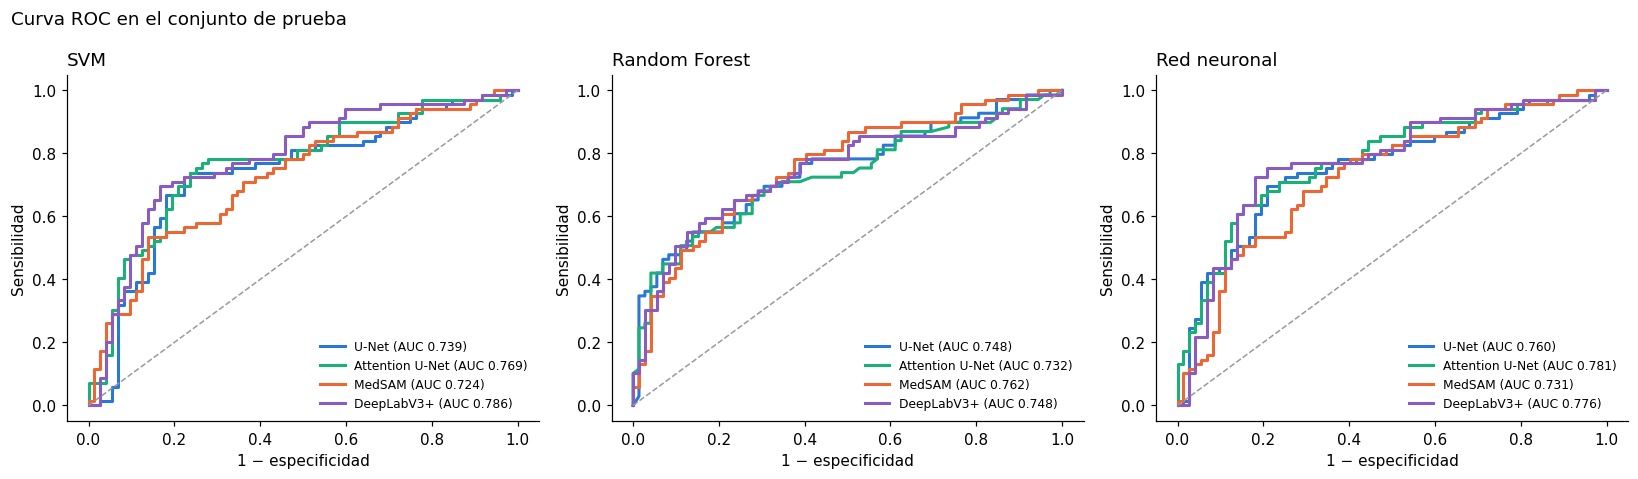

In [11]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 4.4), squeeze=False)
for ax, model_name in zip(axes[0], MODELS):
    for method in METHODS:
        group = predictions[(predictions["model"] == model_name) & (predictions["method"] == method)]
        fpr, tpr, _ = roc_curve(group["tb"], group["score"])
        ax.plot(fpr, tpr, lw=2, color=METHOD_COLORS.get(method),
                label=f"{name(method)} (AUC {roc_auc_score(group['tb'], group['score']):.3f})")
    ax.plot([0, 1], [0, 1], ls="--", color="0.6", lw=1)
    ax.set_xlabel("1 − especificidad"); ax.set_ylabel("Sensibilidad")
    ax.set_title(name(model_name), loc="left"); ax.legend(frameon=False, loc="lower right", fontsize=8)
fig.suptitle("Curva ROC en el conjunto de prueba", x=0.01, ha="left")
fig.tight_layout()
plt.show()

### 7.3 Desempeño por fuente

Las fuentes difieren en adquisición y en la convención de anotación de las máscaras (`01b`, sección 8). Si el desempeño cae en una de ellas, el modelo puede estar aprendiendo la fuente y no la enfermedad.

Prueba tiene 27 imágenes de Montgomery (11 TB y 16 normales) y 114 de Shenzhen (58 TB y 56 normales). Con tan pocas imágenes, el intervalo de Montgomery es amplio y un valor aislado no permite concluir.

In [12]:
by_source = test_metrics[test_metrics["scope"] != "todas"]
display(metrics_table(by_source, ["model", "method", "scope"]))

metric                                                     auc  \
model         method          scope                              
SVM           U-Net           Shenzhen    0.776 [0.679, 0.863]   
                              Montgomery  0.585 [0.369, 0.807]   
              Attention U-Net Shenzhen    0.774 [0.683, 0.859]   
                              Montgomery  0.739 [0.533, 0.914]   
              MedSAM          Shenzhen    0.752 [0.653, 0.838]   
                              Montgomery  0.517 [0.283, 0.739]   
              DeepLabV3+      Shenzhen    0.788 [0.696, 0.871]   
                              Montgomery  0.767 [0.565, 0.934]   
Random Forest U-Net           Shenzhen    0.778 [0.689, 0.858]   
                              Montgomery  0.562 [0.311, 0.812]   
              Attention U-Net Shenzhen    0.749 [0.656, 0.835]   
                              Montgomery  0.648 [0.420, 0.869]   
              MedSAM          Shenzhen    0.797 [0.708, 0.876]   
                              Montgomery  0.534 [0.288, 0.764]   
              DeepLabV3+      Shenzhen    0.758 [0.665, 0.844]   
                              Montgomery  0.670 [0.441, 0.876]   
Red neuronal  U-Net           Shenzhen    0.789 [0.696, 0.872]   
                              Montgomery  0.597 [0.379, 0.808]   
              Attention U-Net Shenzhen    0.790 [0.702, 0.869]   
                              Montgomery  0.716 [0.494, 0.894]   
              MedSAM          Shenzhen    0.757 [0.662, 0.845]   
                              Montgomery  0.574 [0.330, 0.783]   
              DeepLabV3+      Shenzhen    0.780 [0.687, 0.865]   
                              Montgomery  0.773 [0.574, 0.933]   

metric                                            sensibilidad  \
model         method          scope                              
SVM           U-Net           Shenzhen    0.793 [0.679, 0.892]   
                              Montgomery  0.455 [0.154, 0.765]   
              Attention U-Net Shenzhen    0.793 [0.683, 0.892]   
                              Montgomery  0.545 [0.231, 0.857]   
              MedSAM          Shenzhen    0.672 [0.545, 0.792]   
                              Montgomery  0.727 [0.444, 1.000]   
              DeepLabV3+      Shenzhen    0.776 [0.667, 0.877]   
                              Montgomery  0.455 [0.154, 0.765]   
Random Forest U-Net           Shenzhen    0.707 [0.585, 0.825]   
                              Montgomery  0.364 [0.091, 0.667]   
              Attention U-Net Shenzhen    0.638 [0.511, 0.763]   
                              Montgomery  0.455 [0.154, 0.769]   
              MedSAM          Shenzhen    0.707 [0.586, 0.821]   
                              Montgomery  0.636 [0.333, 0.909]   
              DeepLabV3+      Shenzhen    0.707 [0.583, 0.823]   
                              Montgomery  0.455 [0.154, 0.769]   
Red neuronal  U-Net           Shenzhen    0.793 [0.679, 0.892]   
                              Montgomery  0.364 [0.091, 0.667]   
              Attention U-Net Shenzhen    0.759 [0.641, 0.863]   
                              Montgomery  0.455 [0.154, 0.769]   
              MedSAM          Shenzhen    0.672 [0.547, 0.789]   
                              Montgomery  0.727 [0.429, 1.000]   
              DeepLabV3+      Shenzhen    0.793 [0.679, 0.891]   
                              Montgomery  0.364 [0.091, 0.667]   

metric                                           especificidad  \
model         method          scope                              
SVM           U-Net           Shenzhen    0.750 [0.632, 0.857]   
                              Montgomery  0.688 [0.462, 0.909]   
              Attention U-Net Shenzhen    0.714 [0.593, 0.827]   
                              Montgomery  0.812 [0.600, 1.000]   
              MedSAM          Shenzhen    0.732 [0.608, 0.843]   
                              Montgomery  0.375 [0.133, 0.615]   
              DeepLabV3+      Shenzhen

## 8 · Comparación entre técnicas de segmentación

Esta es la pregunta del proyecto. Como todas las técnicas se evalúan sobre las mismas imágenes de prueba, la comparación es **pareada**: en cada remuestreo se resta la métrica de la técnica de referencia a la de la otra técnica. Se comparan todos los pares de `METHODS`; en cada par, la referencia es la que aparece primero.

Se usa el mismo criterio de `02_segmentacion`: **si el intervalo de confianza del 95 % incluye el cero, la diferencia no es concluyente.**

La segunda tabla cuenta las imágenes de prueba cuya predicción cambia al cambiar de técnica. Mide el efecto de la segmentación aunque la métrica global no se mueva, porque un cambio de un caso a otro se puede compensar.

In [13]:
PAIRS = list(combinations(METHODS, 2))  # (referencia, técnica)
point = test_metrics[test_metrics["scope"] == "todas"].set_index(["model", "method", "metric"])["value"]
rows, changes = [], []
for model_name in MODELS:
    selected = predictions[predictions["model"] == model_name]
    for reference, method in PAIRS:
        reference_pred = selected.loc[selected["method"] == reference, "pred"].to_numpy()
        differences = draws[model_name, method] - draws[model_name, reference]
        for metric in METRICS:
            low, high = np.percentile(differences[metric], [2.5, 97.5])
            rows.append({"model": model_name, "reference_method": reference, "method": method, "metric": metric,
                         "reference": point[model_name, reference, metric], "value": point[model_name, method, metric],
                         "difference": point[model_name, method, metric] - point[model_name, reference, metric],
                         "ci_low": low, "ci_high": high, "conclusive": not low <= 0 <= high})
        changed = selected.loc[selected["method"] == method, "pred"].to_numpy() != reference_pred
        changes.append({"modelo": name(model_name), "referencia": name(reference), "técnica": name(method),
                        "predicciones que cambian": f"{changed.sum()} de {len(changed)}"})
comparison = pd.DataFrame(rows)

if comparison.empty:
    print("Se necesita más de una técnica en METHODS para comparar.")
else:
    with pd.option_context("display.max_rows", None):
        display(comparison.assign(
            difference=comparison["difference"].map("{:+.4f}".format),
            ic_95=comparison["ci_low"].map("[{:+.4f}, ".format) + comparison["ci_high"].map("{:+.4f}]".format),
        ).drop(columns=["ci_low", "ci_high"]).set_index(["model", "reference_method", "method", "metric"]).round(4).rename(index=name))
    display(pd.DataFrame(changes).set_index(["modelo", "referencia", "técnica"]))


reference  \
model         reference_method method          metric                            
SVM           U-Net            Attention U-Net auc                      0.7387   
                                               sensibilidad             0.7391   
                                               especificidad            0.7361   
                                               exactitud_balanceada     0.7376   
                                               f1                       0.7338   
                               MedSAM          auc                      0.7387   
                                               sensibilidad             0.7391   
                                               especificidad            0.7361   
                                               exactitud_balanceada     0.7376   
                                               f1                       0.7338   
                               DeepLabV3+      auc                      0.7387   
                                               sensibilidad             0.7391   
                                               especificidad            0.7361   
                                               exactitud_balanceada     0.7376   
                                               f1                       0.7338   
              Attention U-Net  MedSAM          auc                      0.7685   
                                               sensibilidad             0.7536   
                                               especificidad            0.7361   
                                               exactitud_balanceada     0.7449   
                                               f1                       0.7429   
                               DeepLabV3+      auc                      0.7685   
                                               sensibilidad             0.7536   
                                               especificidad            0.7361   
                                               exactitud_balanceada     0.7449   
                                               f1                       0.7429   
              MedSAM           DeepLabV3+      auc                      0.7242   
                                               sensibilidad             0.6812   
                                               especificidad            0.6528   
                                               exactitud_balanceada     0.6670   
                                               f1                       0.6667   
Random Forest U-Net            Attention U-Net auc                      0.7480   
                                               sensibilidad             0.6522   
                                               especificidad            0.7083   
                                               exactitud_balanceada     0.6803   
                                               f1                       0.6667   
                               MedSAM          auc                      0.7480   
                                               sensibilidad             0.6522   
                                               especificidad            0.7083   
                                               exactitud_balanceada     0.6803   
                                               f1                       0.6667   
                               DeepLabV3+      auc                      0.7480   
                                               sensibilidad             0.6522   
                                               especificidad            0.7083   
                                               exactitud_balanceada     0.6803   
                                               f1                       0.6667   
              Attention U-Net  MedSAM          auc                      0.7316   
                                               sensibilidad             0.6087   
                                               espe

predicciones que cambian
modelo        referencia      técnica                                 
SVM           U-Net           Attention U-Net                13 de 141
                              MedSAM                         40 de 141
                              DeepLabV3+                     11 de 141
              Attention U-Net MedSAM                         37 de 141
                              DeepLabV3+                     10 de 141
              MedSAM          DeepLabV3+                     39 de 141
Random Forest U-Net           Attention U-Net                14 de 141
                              MedSAM                         33 de 141
                              DeepLabV3+                     15 de 141
              Attention U-Net MedSAM                         39 de 141
                              DeepLabV3+                     15 de 141
              MedSAM          DeepLabV3+                     38 de 141
Red neuronal  U-Net           Attention U-Net                18 de 141
                              MedSAM                         36 de 141
                              DeepLabV3+                     15 de 141
              Attention U-Net MedSAM                         34 de 141
                              DeepLabV3+                     13 de 141
              MedSAM          DeepLabV3+                     31 de 141

**Lectura.**

*Hechos*

| AUC de prueba [IC 95 %] | U-Net | Attention U-Net | MedSAM | DeepLabV3+ |
|---|---|---|---|---|
| SVM | 0,739 [0,651; 0,820] | 0,769 [0,686; 0,845] | 0,724 [0,638; 0,805] | 0,786 [0,705; 0,859] |
| Random Forest | 0,748 [0,665; 0,827] | 0,732 [0,645; 0,813] | 0,762 [0,683; 0,837] | 0,748 [0,665; 0,828] |
| Red neuronal | 0,760 [0,677; 0,837] | 0,781 [0,703; 0,854] | 0,731 [0,643; 0,810] | 0,776 [0,694; 0,851] |

- **5 de los 90 intervalos son concluyentes** (6 pares × 3 clasificadores × 5 métricas). Todos comparan DeepLabV3+ con otra técnica, y todos a su favor:
  - SVM, AUC frente a U-Net: +0,047 [+0,009; +0,089].
  - Red neuronal frente a Attention U-Net: especificidad +0,111 [+0,031; +0,198], exactitud balanceada +0,063 [+0,015; +0,113] y F1 +0,052 [+0,008; +0,099].
  - Red neuronal, especificidad frente a MedSAM: +0,111 [+0,012; +0,217].
- **Entre U-Net, Attention U-Net y MedSAM ninguna diferencia es concluyente** (45 intervalos).
- **La ventaja de DeepLabV3+ no se repite entre clasificadores.** Su diferencia de AUC con U-Net es +0,047 con SVM, 0,000 con Random Forest y +0,015 con la red neuronal. Con la red neuronal, su AUC queda 0,005 por debajo de la de Attention U-Net, aunque su especificidad, su exactitud balanceada y su F1 queden por encima.
- **MedSAM cambia más predicciones.** Entre MedSAM y cada otra técnica cambian de 31 a 40 de 141 predicciones; entre U-Net, Attention U-Net y DeepLabV3+, de 10 a 18.
- **El orden de las técnicas depende del clasificador.** La AUC de prueba más alta es la de DeepLabV3+ con SVM, la de MedSAM con Random Forest y la de Attention U-Net con la red neuronal. MedSAM tiene la más baja con SVM y con la red neuronal.
- **En desarrollo, MedSAM queda por debajo de las otras técnicas.** Su AUC interna es 0,780 (SVM), 0,783 (Random Forest) y 0,790 (red neuronal), frente a 0,809–0,847. Está por debajo de Attention U-Net en los 5 folds con los tres clasificadores, y por debajo de U-Net en 5 folds con SVM, en 4 con Random Forest y en 3 con la red neuronal.
- **En desarrollo, DeepLabV3+ queda cerca de Attention U-Net.** Su AUC interna es 0,833 (SVM), 0,830 (Random Forest) y 0,837 (red neuronal). Supera a U-Net en 4 de 5 folds con los tres clasificadores, y a Attention U-Net en 3, 2 y 1 folds.

*Interpretación*

- **Cinco intervalos concluyentes de 90 no bastan para afirmar un efecto.** Sin corrección por comparaciones múltiples, con 90 intervalos del 95 % se esperan unos 4 o 5 concluyentes por azar aunque ninguna técnica cambie nada. Es una referencia aproximada, porque los intervalos no son independientes. Además, la diferencia en AUC solo aparece con SVM; con la red neuronal aparece en métricas que dependen del umbral, no en AUC.
- **La diferencia de F1 entre DeepLabV3+ y Attention U-Net puede venir de la semilla.** En desarrollo cambia de signo según la semilla de la red neuronal (sección 6.4), y el intervalo de prueba no incluye ese azar.
- **"No concluyente" no significa "sin efecto".** Los intervalos de la diferencia de AUC con MedSAM van de [−0,131; +0,005] a [−0,037; +0,099]. Con 141 imágenes, los datos son compatibles con diferencias de hasta unas 0,1 en cualquiera de las dos direcciones.
- **Para la pregunta del proyecto:** este experimento no permite afirmar que la técnica de segmentación cambie la AUC, ni que no la cambie. DeepLabV3+ es la técnica con más indicios a favor, pero dependen del clasificador. Sí se ve que la técnica cambia predicciones individuales y qué características usa el modelo (sección 9).
- **Dice y AUC no se movieron igual.** MedSAM tiene un Dice concluyentemente menor (`02_segmentacion`, sección 6.2), y su AUC de prueba no lo es. DeepLabV3+ tiene un Dice mayor que las U-Net por milésimas (`02_segmentacion`, sección 6.4) y la AUC más alta con SVM, pero no con los otros dos clasificadores. No se comprobó la causa.

*Limitaciones*

- **Se evalúa MedSAM con caja a priori**, no MedSAM en general: en val, con cajas manuales, su Dice sube de 0,9042 a 0,97 (`02_segmentacion`, sección 6.3).
- **MedSAM se desarrolló con este dataset** (Tabla 3 del suplemento de Ma et al., 2024). No se pudo determinar qué imágenes usó, así que las imágenes de prueba pueden no ser independientes para este segmentador.
- **DeepLabV3+ parte de un codificador preentrenado en ImageNet** y las U-Net no (`02_segmentacion`, sección 3), así que una diferencia frente a ellas no se puede atribuir solo a la arquitectura.
- **Sin corrección por comparaciones múltiples.** Con una corrección (por ejemplo, Bonferroni) los intervalos serían más anchos; no se comprobó si alguno de los cinco concluyentes seguiría excluyendo el cero.
- **Montgomery.** La AUC de MedSAM en sus 27 imágenes de prueba es 0,517 [0,283; 0,739] con SVM, 0,534 [0,288; 0,764] con Random Forest y 0,574 [0,330; 0,783] con la red neuronal. Es la fuente donde sus máscaras fallan más, pero los intervalos no permiten concluir. DeepLabV3+ tiene la AUC más alta en Montgomery con SVM (0,767 [0,565; 0,934]) y con la red neuronal (0,773 [0,574; 0,933]), y con 27 imágenes tampoco permite concluir.
- **Una sola semilla** en las redes de segmentación.

## 9 · Importancia de características

Importancia de Random Forest (reducción media de impureza), calculada con el modelo entrenado en desarrollo. Responde una pregunta complementaria: **¿la técnica de segmentación cambia qué características usa el modelo?**, aunque la AUC no cambie.

Las características correlacionadas se reparten la importancia, así que se lee **por grupo** (`03_radiomica`, secciones 2 y 3). `Energy` merece atención aparte: depende sobre todo del tamaño de la máscara en las redes (ρ con el área: 0,86 en U-Net, 0,84 en Attention U-Net, 0,86 en DeepLabV3+ y 0,55 en MedSAM; el valor de DeepLabV3+ se calculó con el mismo código de `03_radiomica`, que todavía no incluye esa técnica), así que es la característica que más directamente recibe el efecto de la segmentación.

method                     U-Net  Attention U-Net  MedSAM  DeepLabV3+
model         group                                                  
Random Forest Posición     0.130            0.118   0.275       0.112
              Dispersión   0.333            0.325   0.171       0.311
              Complejidad  0.080            0.080   0.090       0.078
              Magnitud     0.104            0.122   0.056       0.109
              Sin grupo    0.353            0.354   0.408       0.390

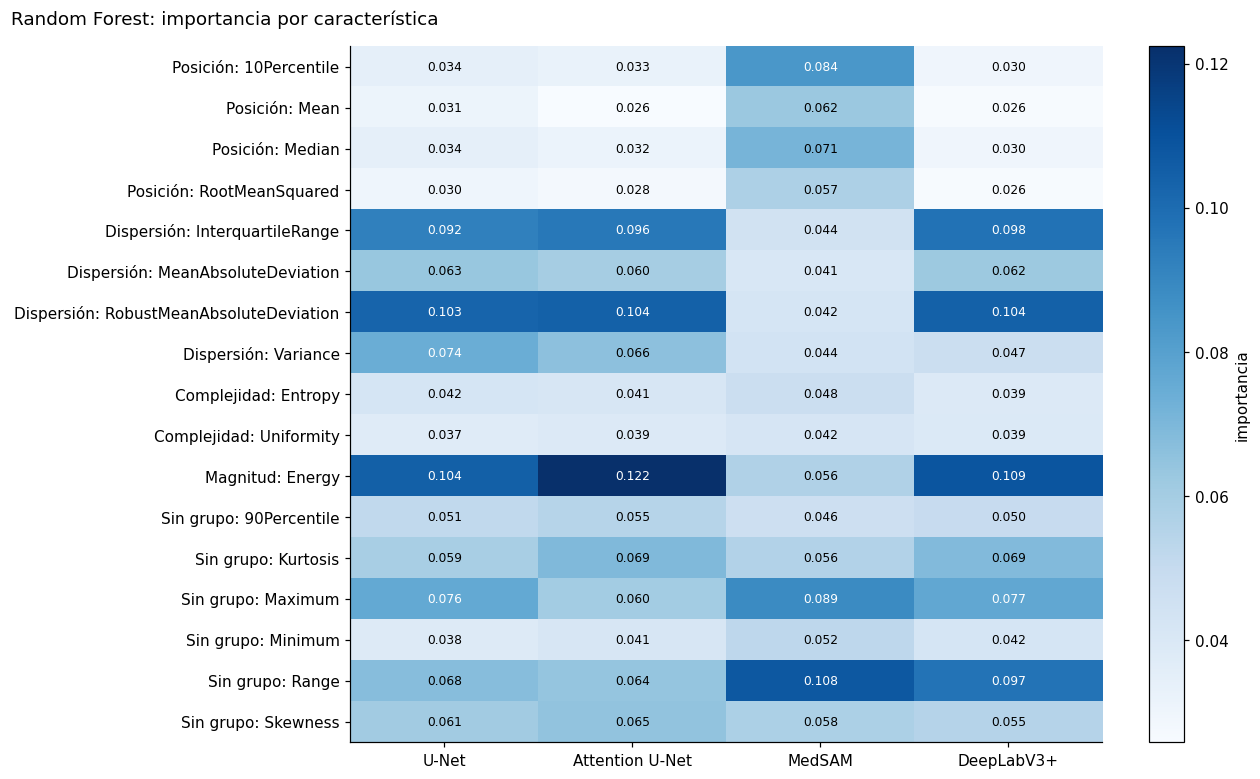

In [14]:
FEATURE_GROUPS = {
    "Posición": ["10Percentile", "Mean", "Median", "RootMeanSquared"],
    "Dispersión": ["InterquartileRange", "MeanAbsoluteDeviation", "RobustMeanAbsoluteDeviation", "Variance"],
    "Complejidad": ["Entropy", "Uniformity"],
    "Magnitud": ["Energy"],
}
NO_GROUP = "Sin grupo"
GROUP_OF = {feature: group for group, members in FEATURE_GROUPS.items() for feature in members}

importances = pd.DataFrame([
    {"model": model_name, "method": method, "feature": feature, "group": GROUP_OF.get(feature, NO_GROUP), "importance": value}
    for (model_name, method), search in searches.items() if hasattr(search.best_estimator_[-1], "feature_importances_")
    for feature, value in zip(FEATURES, search.best_estimator_[-1].feature_importances_)
])

if importances.empty:
    print("Ningún modelo de MODELS expone feature_importances_.")
else:
    group_order = [*FEATURE_GROUPS, NO_GROUP]
    by_group = importances.pivot_table(index=["model", "group"], columns="method", values="importance", aggfunc="sum")
    display(by_group[METHODS].reindex(group_order, level="group").round(3).rename(index=name, columns=name))

    order = sorted(FEATURES, key=lambda f: (group_order.index(GROUP_OF.get(f, NO_GROUP)), f))
    for model_name, group in importances.groupby("model", sort=False):
        data = group.pivot(index="feature", columns="method", values="importance").loc[order, METHODS]
        fig, ax = plt.subplots(figsize=(1.6 * len(METHODS) + 5.5, 0.34 * len(order) + 1.4))
        image = ax.imshow(data.to_numpy(), cmap="Blues", aspect="auto")
        ax.set_xticks(range(len(METHODS)), [name(m) for m in METHODS])
        ax.set_yticks(range(len(order)), [f"{GROUP_OF.get(f, NO_GROUP)}: {f}" for f in order])
        for (i, j), v in np.ndenumerate(data.to_numpy()):
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8,
                    color="white" if v > data.to_numpy().max() * 0.6 else "black")
        fig.colorbar(image, ax=ax, label="importancia")
        fig.suptitle(f"{name(model_name)}: importancia por característica", x=0.01, ha="left")
        fig.tight_layout()
        plt.show()

**Lectura.** Las tres redes reparten la importancia de forma parecida, y MedSAM no:

| Grupo | U-Net | Attention U-Net | DeepLabV3+ | MedSAM |
|---|---|---|---|---|
| Posición | 0,130 | 0,118 | 0,112 | 0,275 |
| Dispersión | 0,333 | 0,325 | 0,311 | 0,171 |
| Magnitud (`Energy`) | 0,104 | 0,122 | 0,109 | 0,056 |

Los grupos se definieron con U-Net y Attention U-Net. Con DeepLabV3+ aparecen los mismos cuatro grupos con el criterio de `03_radiomica` (sección 2), que todavía no incluye esa técnica. En MedSAM, `10Percentile` no alcanza el umbral con el grupo Posición (`03_radiomica`, sección 2); sin esa característica, Posición suma 0,190, y sigue por encima de las redes. Estas importancias salen de un solo modelo por técnica, sin intervalo de confianza.

## 10 · Guardado

Se guardan nueve archivos en `results/classification/<dataset>/<familias>/`. La carpeta incluye las familias para que dos experimentos no se sobrescriban.

| Archivo | Contenido |
|---|---|
| `cv_metrics.csv` | AUC de cada técnica × modelo × fold interno |
| `best_params.csv` | Hiperparámetros elegidos y AUC interna |
| `test_predictions.csv` | Puntaje y predicción de cada imagen de prueba |
| `test_metrics.csv` | Métricas de prueba con intervalo de confianza, globales y por fuente |
| `test_comparison.csv` | Diferencias entre cada par de técnicas |
| `importances.csv` | Importancia de cada característica (modelos que la exponen) |
| `mlp_selection.csv` | Red neuronal: AUC interna de cada combinación de la rejilla |
| `mlp_seeds.csv` | Red neuronal: AUC interna por semilla, con 1 y con 5 redes |
| `mlp_variants.csv` | Red neuronal: AUC interna de las opciones descartadas |

In [15]:
CLF_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
outputs = {"cv_metrics.csv": cv_metrics, "best_params.csv": best_params, "test_predictions.csv": predictions,
           "test_metrics.csv": test_metrics, "test_comparison.csv": comparison, "importances.csv": importances,
           "mlp_selection.csv": mlp_selection, "mlp_seeds.csv": mlp_seeds, "mlp_variants.csv": mlp_variants}
for file_name, df in outputs.items():
    df.to_csv(CLF_RESULTS_DIR / file_name, index=False)
print(f"Guardado en {CLF_RESULTS_DIR.relative_to(ROOT)}: {', '.join(outputs)}")

Guardado en results/classification/montgomery_shenzhen/firstorder: cv_metrics.csv, best_params.csv, test_predictions.csv, test_metrics.csv, test_comparison.csv, importances.csv, mlp_selection.csv, mlp_seeds.csv, mlp_variants.csv
